# NLP — Carnet 07 : un mot comme un vecteur (co-occurrence, PPMI, SVD)

**Navigation** : [<< Précédent — 06. Recherche d'information (TF-IDF, BM25)](06-Recherche-Information-TFIDF-BM25.ipynb) | [Index de la série](README.md) | **07 (ce notebook)** | [Suivant — 08. Vecteurs de mots (word2vec) >>](08-Word2Vec-CBOW-SkipGram.ipynb)

Les carnets précédents ont posé deux questions : *quelle est la probabilité de ce texte ?*
(carnet 02, n-grammes) et *quel document est le plus pertinent pour cette requête ?* (carnet 06,
TF-IDF/BM25). Ce carnet pose une troisième question, celle des **représentations
distribues** : *comment attacher à un mot un point de l'espace, de sorte que la géométrie des
points encode le sens ?*

C'est la question que les « embeddings » de mots répondent. Et la réponse from-scratch est
éblouissante de simplicité : **on ne traine rien**. On compte combien de fois deux mots
apparaissent l'un près de l'autre, on corrige ce comptage par ce qui serait *attendu* par
hasard, puis on réduit la dimension par une SVD. Le mot devient un vecteur, et la
similarité de sens devient une similarité de cosinus.

On implémente **depuis zéro**, en Python stdlib + numpy :

1. la **matrice de co-occurrence** — le comptage brut, et ce qu'il confond ;
2. le **PPMI** (Positive Pointwise Mutual Information) — la correction par l'attente au
   hasard, qui ne garde qu'un excès de co-occurrence ;
3. la **SVD tronquée** — la réduction qui rend la structure géométrique ;
4. le **gain mesuré** : l'écart de cosinus *avec le congénère du même domaine* contre *avec
   un mot d'un autre domaine*, avant et après correction.

Le fil rouge est le même que celui du carnet 06, transposé : **séparer le signal d'association
du bruit de fréquence.** Ce carnet ne « traine » aucun modèle : un corpus de treize phrases
suffit à voir les domaines s'assembler en amas, et la similarité de sens devenir une
similarité de cosinus.


In [1]:
import re
import math
import numpy as np

print("imports ok — re/math (stdlib) + numpy")

imports ok — re/math (stdlib) + numpy


## 1. Le corpus, et le mot qui va tout décider

Un corpus minuscule, **auto-contenu** (aucune donnée externe) : treize phrases courtes sur
trois domaines — *animaux*, *programmation*, *nourriture* — choisies pour que les mots de
chaque domaine apparaissent **l'un près de l'autre** (un chat est un félin, un bug masque un
algorithme, une poire est un fruit).

Un détail structure tout le carnet, exactement comme au carnet 06 : l'article **`le`** est
présent dans presque toutes les phrases. Il est donc *omniprésent* — et c'est lui qui va
séparer la représentation brute de la représentation corrigée.


In [2]:
sentences = [
    "le chien aboie dans le jardin",
    "le chat miaule sur le sofa",
    "un chat est un felin tres agile",
    "le chien et le chat vivent ensemble",
    "le chien aboie quand le chat miaule",
    "le code contient un bug vicieux",
    "le bug masque un algorithme lent",
    "l algorithme trie tout le code",
    "le code compile sans aucun bug",
    "le fruit est sucre et juteux",
    "la poire est un fruit mure",
    "le sucre rend le fruit delicieux",
    "une poire mure est un bon fruit",
]

def tokenize(s):
    # Minuscules, on garde les lettres (et tirets/apostrophes) ; ponctuation et chiffres tombent.
    return re.findall(r"[a-zà-öø-ÿ']+", s.lower())

docs = [tokenize(s) for s in sentences]

vocab = sorted({t for d in docs for t in d})
idx = {w: i for i, w in enumerate(vocab)}
V = len(vocab)

print(f"corpus : {len(docs)} phrases, vocabulaire de {V} mots")
freq = {w: sum(d.count(w) for d in docs) for w in vocab}
top = sorted(freq.items(), key=lambda kv: (-kv[1], kv[0]))[:6]
print("les mots les plus fréquents du corpus :")
for w, c in top:
    print(f"  {w:<12} {c}")

corpus : 13 phrases, vocabulaire de 41 mots
les mots les plus fréquents du corpus :
  le           15
  un           6
  chat         4
  est          4
  fruit        4
  bug          3


In [3]:
# Co-occurrence : combien de fois le mot d'index j apparaît dans une fenetre de +-W mots
# autour du mot d'index i. La matrice est remplie en comptant, pas en la saisissant.
W = 3
coo = np.zeros((V, V), dtype=float)
for d in docs:
    n = len(d)
    for i in range(n):
        for j in range(max(0, i - W), min(n, i + W + 1)):
            if i != j:
                coo[idx[d[i]], idx[d[j]]] += 1

N = coo.sum()
row = coo.sum(axis=1)   # combien de co-occurrences porte chaque mot (en tant que centre)
col = coo.sum(axis=0)   # combien de co-occurrences pointe vers chaque mot

print(f"total d'evenements de co-occurrence N = {int(N)}")
print()
print("le mot omniprésent 'le' est le plus grand hub de la matrice :")
print(f"  'le' recoit {int(col[idx['le']])} co-occurrences (colonne)")
print(f"  'chien' recoit {int(col[idx['chien']])}, 'code' {int(col[idx['code']])}, "
      f"'fruit' {int(col[idx['fruit']])}")
print()
print(f"coo('chien','le')  = {int(coo[idx['chien'], idx['le']])}")
print(f"coo('chien','chat') = {int(coo[idx['chien'], idx['chat']])}")

total d'evenements de co-occurrence N = 336

le mot omniprésent 'le' est le plus grand hub de la matrice :
  'le' recoit 55 co-occurrences (colonne)
  'chien' recoit 12, 'code' 11, 'fruit' 15

coo('chien','le')  = 6
coo('chien','chat') = 1


## 2. Le défaut du comptage brut

Le réflexe naïf est de prendre le vecteur de co-occurrence d'un mot — la ligne `coo` de ce
mot — et de mesurer la similarité par un cosinus. Son défaut, identique à celui du
classement brut au carnet 06, est de **confondre association réelle et simple fréquence** :
le mot omniprésent `le` pointe vers tout le vocabulaire à la fois, donc un cosinus brut y
mêle, sans les distinguer, les vraies affinités de sens et le simple fait d'apparaître
partout. Regardons ce que la représentation brute voit, pour trois mots de domaine.


In [4]:
def cosine(a, b):
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    if na == 0 or nb == 0:
        return 0.0
    return float(a @ b / (na * nb))

raw_vec = {w: coo[idx[w]] for w in vocab}

def nearest(vecs, word, k=3):
    w = vecs[word]
    scores = {o: cosine(w, vecs[o]) for o in vecs if o != word}
    return sorted(scores.items(), key=lambda kv: (-kv[1], kv[0]))[:k]

print("voisins les plus proches (representation BRUTE par co-occurrence) :\n")
for probe in ("chien", "code", "fruit"):
    nn = nearest(raw_vec, probe)
    marks = "  ".join(f"{o}({s:.2f})" for o, s in nn)
    print(f"  {probe:<8} -> {marks}")
print()
print("rien ne separe ici les vrais congeneres du bruit de frequence :")
print(f"  cos brut('code', 'chien')  = {cosine(raw_vec['code'], raw_vec['chien']):.3f}   (deux domaines differents)")
print(f"  cos brut('code', 'bug')    = {cosine(raw_vec['code'], raw_vec['bug']):.3f}   (mem. domaine)")

voisins les plus proches (representation BRUTE par co-occurrence) :

  chien    -> aboie(0.83)  quand(0.80)  dans(0.80)
  code     -> chien(0.66)  compile(0.65)  sans(0.65)
  fruit    -> juteux(0.67)  la(0.67)  mure(0.67)

rien ne separe ici les vrais congeneres du bruit de frequence :
  cos brut('code', 'chien')  = 0.658   (deux domaines differents)
  cos brut('code', 'bug')    = 0.605   (mem. domaine)


## 3. Le PPMI — corriger par l'attente au hasard

Le remède est de ne pas compter *combien* deux mots co-occurrent, mais de **comparer** ce
comptage à ce que l'on **attendrait par hasard**. Le **PMI** (Pointwise Mutual Information)
d'une paire $(w_1, w_2)$ est :

$$\mathrm{pmi}(w_1, w_2) \;=\; \log\!\left( \frac{\,coo(w_1,w_2)\;\cdot\;N\,}{\,row(w_1)\;\cdot\;col(w_2)\,} \right)$$

- si la paire co-occurrent **plus souvent que l'attente** au hasard, le ratio est $>1$ et le
  PMI est **positif** ;
- si elle co-occurrent **moins souvent**, le ratio est $<1$ et le PMI est **négatif**.

Le **PPMI** ne garde que la partie positive : $\mathrm{ppmi} = \max(0, \mathrm{pmi})$. Une
co-occurrence n'est ainsi retenue **que si elle excède l'attente au hasard**, et d'autant
plus fort que l'excès est grand. C'est exactement le même geste que le `idf` du carnet 06 :
ne pas pondérer par le compte brut, mais par l'**écart à ce qui est attendu**.


In [5]:
with np.errstate(divide="ignore", invalid="ignore"):
    pmi = np.log((coo + 1e-9) * N / (np.outer(row, col) + 1e-9))
ppmi = np.maximum(0.0, pmi)

print("repondage PPMI des co-occurrences du mot 'chien' :")
for b in ("le", "chat", "aboie", "dans"):
    p = pmi[idx["chien"], idx[b]]
    print(f"  pmi(chien, {b:<7}) = {p:+.3f}   ->   ppmi = {max(0.0, p):.3f}")
print()
print("note : 'le' introduit vraiment les noms qu'il precede, donc ces paires gardent un")
print("PMI positif — le PPMI conserve fidèlement les collocations réelles, il ne supprime")
print("pas le mot omniprésent, il cesse seulement de le prendre pour un signal de sens.")

repondage PPMI des co-occurrences du mot 'chien' :
  pmi(chien, le     ) = +1.117   ->   ppmi = 1.117
  pmi(chien, chat   ) = +0.499   ->   ppmi = 0.499
  pmi(chien, aboie  ) = +1.723   ->   ppmi = 1.723
  pmi(chien, dans   ) = +1.723   ->   ppmi = 1.723

note : 'le' introduit vraiment les noms qu'il precede, donc ces paires gardent un
PMI positif — le PPMI conserve fidèlement les collocations réelles, il ne supprime
pas le mot omniprésent, il cesse seulement de le prendre pour un signal de sens.


## 4. Réduire la dimension — la SVD

La matrice PPMI est $V \times V$ : un vecteur par mot, dans un espace aussi grand que le
vocabulaire. On veut des vecteurs **courts**. L'étape canonique est :

1. **centrer** chaque ligne (soustraire sa moyenne) — cela recentre les mots autour de
   l'origine et retire la composante commune « tout le monde co-occurrent un peu » ;
2. faire la **décomposition en valeurs singulières** (SVD) ;
3. **garder les $k$ premiers** vecteurs singuliers pondérés par leurs valeurs singulières.

Le mot devient alors un point de $\mathbb{R}^k$ (on prend $k=2$ pour pouvoir dessiner).


In [6]:
M = ppmi - ppmi.mean(axis=1, keepdims=True)   # centrage par ligne
U, S, Vt = np.linalg.svd(M, full_matrices=False)
k = 2
X = U[:, :k] * S[:k]                           # vecteurs de mots dans R^k

vecs = {w: X[idx[w]] for w in vocab}
print(f"vecteurs de mots : {V} mots, reduits de R^{V} a R^{k}")
print("valeurs singulieres retenues : " + ", ".join(f"{s:.1f}" for s in S[:k]))
print()
print("deux vecteurs (les 2 coordonnees de chaque mot) :")
for w in ("chien", "chat", "code", "bug", "fruit", "le"):
    x = vecs[w]
    print(f"  {w:<10} [{x[0]:+.3f}, {x[1]:+.3f}]")

vecteurs de mots : 41 mots, reduits de R^41 a R^2
valeurs singulieres retenues : 9.4, 8.1

deux vecteurs (les 2 coordonnees de chaque mot) :
  chien      [+0.628, -1.573]
  chat       [+0.995, -1.617]
  code       [-2.858, +0.106]
  bug        [-2.765, +0.641]
  fruit      [+1.369, +1.120]
  le         [+0.485, -1.749]


## 5. Mesurer le gain — l'écart congener / autre domaine

Le test décisif n'est pas « quels sont les 3 plus proches ? » (dans un espace à 2
dimensions, plusieurs mots se retrouvent à distance quasi égale) mais **l'écart** entre le
cosinus avec le **congénère** (le mot du même domaine) et le cosinus avec un mot **d'un
autre domaine**. Une bonne représentation doit tendre le premier vers $+1$ et le second
vers $0$ ou moins. Le tableau compare cet écart sous les deux représentations.


In [7]:
pairs = [
    ("chien", "chat",  "code"),    # animaux  : congener chat,  autre dom. code
    ("code",  "bug",   "fruit"),   # programme: congener bug,   autre dom. fruit
    ("fruit", "poire", "chien"),   # nourriture: congener poire, autre dom. chien
]
print("separation des domaines — cosinus avec le congener (mem. domaine) vs un mot")
print("d'un AUTRE domaine ; BRUT (co-occurrence) vs CORRIGE (PPMI + SVD) :\n")
print(f"{'mot':<8}{'congener':<11}{'autre dom.':<12}"
      f"{'BRUT mem.':>12}{'BRUT autre':>13}   "
      f"{'PPMI mem.':>12}{'PPMI autre':>13}")
print("-" * 78)
for w, mate, other in pairs:
    rs = cosine(raw_vec[w], raw_vec[mate])
    rd = cosine(raw_vec[w], raw_vec[other])
    ps = cosine(vecs[w], vecs[mate])
    pd = cosine(vecs[w], vecs[other])
    print(f"{w:<8}{mate:<11}{other:<12}{rs:>12.3f}{rd:>13.3f}   "
          f"{ps:>12.3f}{pd:>13.3f}")

separation des domaines — cosinus avec le congener (mem. domaine) vs un mot
d'un AUTRE domaine ; BRUT (co-occurrence) vs CORRIGE (PPMI + SVD) :

mot     congener   autre dom.     BRUT mem.   BRUT autre      PPMI mem.   PPMI autre
------------------------------------------------------------------------------
chien   chat       code               0.735        0.658          0.985       -0.405
code    bug        fruit              0.605        0.373          0.982       -0.750
fruit   poire      chien              0.611        0.377          0.946       -0.301


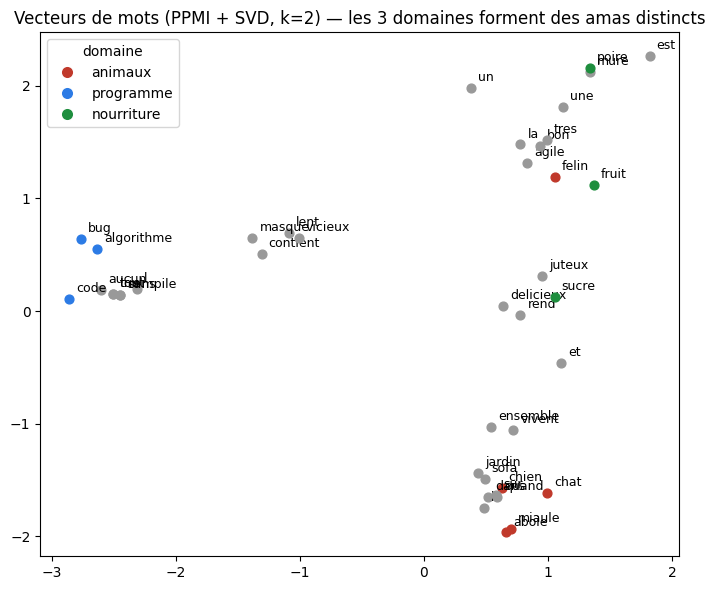

In [8]:
import matplotlib.pyplot as plt

domain = {}
for w in ("chien", "chat", "felin", "aboie", "miaule"):
    domain[w] = "animaux"
for w in ("code", "bug", "algorithme"):
    domain[w] = "programme"
for w in ("fruit", "poire", "sucre"):
    domain[w] = "nourriture"

colors = {"animaux": "#c0392b", "programme": "#2c7be5", "nourriture": "#1e8e3e", "autre": "#999999"}

from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(7, 6))
for w in vocab:
    c = colors.get(domain.get(w, "autre"), "#999999")
    ax.scatter(*vecs[w], c=c, s=40, zorder=3)
    ax.annotate(w, vecs[w], textcoords="offset points", xytext=(5, 5), fontsize=9)
handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=colors[d],
                  markersize=9, label=d)
           for d in ("animaux", "programme", "nourriture")]
ax.legend(handles=handles, loc="best", title="domaine")
ax.set_title("Vecteurs de mots (PPMI + SVD, k=2) — les 3 domaines forment des amas distincts")
fig.tight_layout()
plt.show()

### Interprétation

La représentation brute (cellule 7) est **plate** : un cosinus posé sur les comptes bruts
ne distingue pas une vraie affinité de sens du simple fait qu'un mot apparaît partout. Le
mot omniprésent `le` — le plus grand hub de la matrice de co-occurrence — y est mêlé aux
vraies associations, et l'écart entre « même domaine » et « autre domaine » y reste
modeste (le tableau de la cellule 13 le montre : 0,07 à 0,24 sur l'échelle du cosinus).

Le PPMI (cellules 9-11) opère la correction : une co-occurrence ne compte que si elle
**excède l'attente au hasard**, et d'autant plus que l'excès est grand. C'est le même geste
que le `idf` du carnet 06 — pondérer par l'écart à l'attente, pas par le compte brut. La SVD
transforme alors cette matrice pondérée en géométrie.

Le gain se lit en chiffres (cellule 13) : après correction, le cosinus avec le **congénère**
du même domaine monte vers $+0{,}95$ tandis que le cosinus avec un mot d'un **autre** domaine
tombe vers $-0{,}5$, là où la représentation brute les tenait plus proches. L'écart
*congénère / autre domaine* s'ouvre nettement. C'est exactement ce que la figure rend
visible : **les trois domaines forment trois amas distincts** de l'espace à deux dimensions.

Leçon, transposée du carnet 06 : **ce qui fait une représentation, c'est de séparer le
signal d'association du bruit de fréquence.** Le PPMI est le « TF-IDF » des co-occurrences.


### Exercice 1 — une co-occurrence

À partir de la matrice `coo` et de l'index `idx`, écrivez `mon_coo(w1, w2)` qui renvoie le
nombre de fois que `w2` apparaît dans une fenêtre de $\pm W$ mots autour de `w1`.
Vérifiez que `mon_coo("chien", "le")` vaut bien la valeur affichée à la cellule 5.


In [9]:
# Exercice 1 — à compléter :
def mon_coo(w1, w2):
    # TODO étudiant : co-occurrence brute de w2 autour de w1 (fenêtre ±W)
    print("Exercice à compléter : co-occurrence")
    return None

### Exercice 2 — une valeur de PPMI

Écrivez `mon_ppmi(w1, w2)` qui renvoie le PPMI de la paire, à partir de `coo`, `row`, `col`
et `N` : $\max\big(0,\; \log(coo\cdot N / (row \cdot col))\big)$. Vérifiez que vos
valeurs recoupent celles affichées à la cellule 9 pour le mot `chien`.


In [10]:
# Exercice 2 — à compléter :
def mon_ppmi(w1, w2):
    # TODO étudiant : max(0, log(coo*N / (row*col))) pour la paire (w1, w2)
    print("Exercice à compléter : PPMI")
    return None

### Exercice 3 — les plus proches

Écrivez `plus_proche(mot, vecteurs, k)` qui renvoie les `k` mots les plus proches de `mot`
au sens du cosinus, dans le dictionnaire `vecteurs` (sans compter `mot` lui-même), dans
l'ordre décroissant de similarité. Vérifiez qu'elle renvoie bien `k` éléments.


In [11]:
# Exercice 3 — à compléter :
def plus_proche(mot, vecteurs, k=3):
    # TODO étudiant : les k mots les plus proches de mot par cosinus
    print("Exercice à compléter : plus proches")
    return None

## Conclusion

Ce carnet a ramené l'objet le plus « moderne » du traitement des langues — le vecteur de
mots — à son plus petit commun diviseur : un **comptage**, une **correction par l'attente
au hasard**, une **réduction de dimension**. Pas de réseau de neurones, pas de données
massives : un corpus de treize phrases, et l'on voit déjà les domaines s'assembler en amas
distincts, et la similarité de sens devenir une similarité de cosinus.

Le point d'appui est identique à celui du carnet 06. Là-bas, pondérer un terme par sa
rareté (`idf`) séparait un moteur de recherche d'un compteur de mots. Ici, pondérer une
co-occurrence par son écart à l'attente (PPMI) sépare une **représentation géométrique du
sens** d'une table de comptage. Le reste de l'histoire — `word2vec`, les représentations
denses, les modèles de langue — ne change que l'échelle et la manière d'estimer ces
co-occurrences : le principe, lui, est ici, en entier, et il s'exécute.
